In [ ]:
# Run this first before anything else
from google.colab import drive
drive.mount('/content/drive')

import os

# Set up all folder paths
project_folder   = '/content/drive/MyDrive/FraudDetection'
data_folder      = project_folder + '/data'
processed_folder = project_folder + '/data/processed'
models_folder    = project_folder + '/models'
dataset_file     = project_folder + '/dataset/creditcard.csv'

# Old variable names that the save cell uses
PROC_PATH = processed_folder
MOD_PATH  = models_folder

# Create folders if they do not exist
os.makedirs(data_folder,      exist_ok=True)
os.makedirs(processed_folder, exist_ok=True)
os.makedirs(models_folder,    exist_ok=True)

print('Setup complete!')
print('Processed folder:', PROC_PATH)
print('Models folder:   ', MOD_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup complete!
Processed folder: /content/drive/MyDrive/FraudDetection/data/processed
Models folder:    /content/drive/MyDrive/FraudDetection/models


In [ ]:
import pandas as pd
import numpy as np

# Load the dataset from the CSV file
# We always load it fresh here instead of reusing it from another notebook
df = pd.read_csv(dataset_file)

# Print a summary of what we loaded
print('--------------------------------------------------')
print('Dataset Summary')
print('--------------------------------------------------')
print('Total number of transactions:', len(df))
print('Number of fraud cases:       ', df['Class'].sum())
print('Fraud percentage:            ', round(df['Class'].mean() * 100, 4), '%')
print('Number of columns:           ', df.shape[1])
print()

# Check that the dataset is the correct one
# The original ULB dataset should have exactly 284,807 rows and 492 fraud cases
# If the numbers are different, it means the file has been modified or corrupted
correct_rows  = 284807
correct_fraud = 492

if len(df) == correct_rows and df['Class'].sum() == correct_fraud:
    print('Dataset looks correct. Safe to continue.')
    print('Amount column present:', 'Amount' in df.columns)
    print('Time column present:  ', 'Time' in df.columns)
else:
    print('Something is wrong with the dataset.')
    print('Expected:', correct_rows, 'rows and', correct_fraud, 'fraud cases')
    print('Found:   ', len(df), 'rows and', int(df['Class'].sum()), 'fraud cases')
    print()
    print('Please fix the dataset before running any further steps.')

print('--------------------------------------------------')

--------------------------------------------------
Dataset Summary
--------------------------------------------------
Total number of transactions: 284807
Number of fraud cases:        492
Fraud percentage:             0.1727 %
Number of columns:            31

Dataset looks correct. Safe to continue.
Amount column present: True
Time column present:   True
--------------------------------------------------


In [ ]:
from sklearn.preprocessing import StandardScaler
import pickle

# Check columns exist before scaling
print('Before scaling:')
print('  Amount exists:', 'Amount' in df.columns)
print('  Time exists:  ', 'Time' in df.columns)
print()

# Create separate scalers for Amount and Time
# StandardScaler transforms values to mean=0, standard deviation=1
# This puts Amount and Time in the same range as V1-V28
# Without this large Amount values would dominate the model unfairly
scaler_amount = StandardScaler()
scaler_time   = StandardScaler()

# Scale Amount (ranges 0 to 25,000 euros)
if 'Amount' in df.columns:
    # fit_transform learns the mean/std AND applies the transformation
    df['Amount_Scaled'] = scaler_amount.fit_transform(df[['Amount']])
    df.drop('Amount', axis=1, inplace=True)
    print('Amount: scaled and original removed')
else:
    print('Amount already removed — reload CSV in Cell 1')

# Scale Time (ranges 0 to 172,792 seconds)
if 'Time' in df.columns:
    df['Time_Scaled'] = scaler_time.fit_transform(df[['Time']])
    df.drop('Time', axis=1, inplace=True)
    print('Time:   scaled and original removed')
else:
    print('Time already removed — reload CSV in Cell 1')

print()
print('After scaling:')
print(f'  Shape: {df.shape}')
print(f'  Fraud count: {df["Class"].sum()}')
print(f'  Columns: {df.shape[1]}')

Before scaling:
  Amount exists: True
  Time exists:   True

Amount: scaled and original removed
Time:   scaled and original removed

After scaling:
  Shape: (284807, 31)
  Fraud count: 492
  Columns: 31


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and labels
# X = all input features the model uses to predict
# y = Class column — what we want to predict (0=legit, 1=fraud)
X = df.drop('Class', axis=1)
y = df['Class']

print(f'Features shape: {X.shape}')
print(f'Labels shape:   {y.shape}')
print(f'Total fraud:    {y.sum()}')
print()

# CRITICAL: Split BEFORE applying SMOTE
# Test set must never contain synthetic data
# test_size=0.2 = 80% training 20% testing
# stratify=y = both sets keep the same 0.17% fraud rate
# random_state=42 = same split every time we run
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('='*50)
print('SPLIT RESULTS')
print('='*50)
print(f'Training rows:  {X_train.shape[0]:,}')
print(f'Test rows:      {X_test.shape[0]:,}')
print()
print(f'Train fraud:    {y_train.sum()} ({y_train.mean()*100:.4f}%)')
print(f'Test fraud:     {y_test.sum()}  ({y_test.mean()*100:.4f}%)')
print()

# Test set must have natural 0.17% fraud rate
if y_test.mean() < 0.005:
    print('CORRECT: Test set has 0.17% natural fraud rate')
    print('Safe to apply SMOTE to training only')
else:
    print('ERROR: Test fraud rate too high')
    print('Dataset may be corrupted')
print('='*50)

Features shape: (284807, 30)
Labels shape:   (284807,)
Total fraud:    492

SPLIT RESULTS
Training rows:  227,845
Test rows:      56,962

Train fraud:    394 (0.1729%)
Test fraud:     98  (0.1720%)

CORRECT: Test set has 0.17% natural fraud rate
Safe to apply SMOTE to training only


"SMOTE creates fake fraud examples to balance the training data so the model learns to actually detect fraud instead of ignoring it."

BEFORE SMOTE (training set only):
  Legitimate: 227,451
  Fraud:      394
  Fraud rate: 0.1729%

AFTER SMOTE (training set only):
  Legitimate: 227,451
  Fraud:      227,451
  Fraud rate: 50.00%

TEST SET UNCHANGED:
  Legitimate: 56,864
  Fraud:      98
  Fraud rate: 0.1720%



NameError: name 'DATA_PATH' is not defined

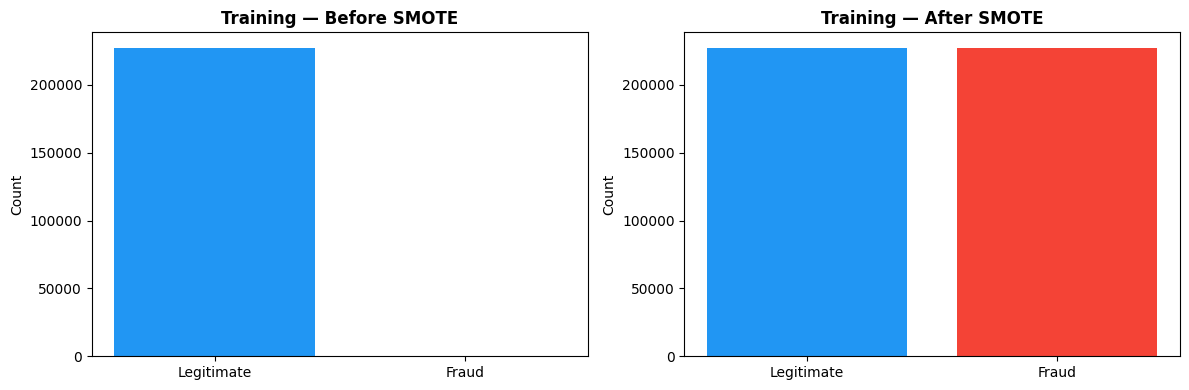

In [ ]:
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt

# Show counts before SMOTE
print('BEFORE SMOTE (training set only):')
print(f'  Legitimate: {(y_train==0).sum():,}')
print(f'  Fraud:      {(y_train==1).sum()}')
print(f'  Fraud rate: {y_train.mean()*100:.4f}%')
print()

# Apply SMOTE to training set ONLY
# SMOTE creates new synthetic fraud examples by:
# 1. Taking an existing fraud transaction
# 2. Finding its 5 nearest fraud neighbours
# 3. Creating a new point somewhere between them
# This creates varied new fraud examples instead of just copying
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('AFTER SMOTE (training set only):')
print(f'  Legitimate: {(y_train_sm==0).sum():,}')
print(f'  Fraud:      {(y_train_sm==1).sum():,}')
print(f'  Fraud rate: {y_train_sm.mean()*100:.2f}%')
print()

# Confirm test set was NOT touched
print('TEST SET UNCHANGED:')
print(f'  Legitimate: {(y_test==0).sum():,}')
print(f'  Fraud:      {(y_test==1).sum()}')
print(f'  Fraud rate: {y_test.mean()*100:.4f}%')
print()

# Before vs After chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    ['Legitimate', 'Fraud'],
    [int((y_train==0).sum()), int((y_train==1).sum())],
    color=['#2196F3', '#F44336']
)
axes[0].set_title('Training — Before SMOTE', fontweight='bold')
axes[0].set_ylabel('Count')

axes[1].bar(
    ['Legitimate', 'Fraud'],
    [int((y_train_sm==0).sum()), int((y_train_sm==1).sum())],
    color=['#2196F3', '#F44336']
)
axes[1].set_title('Training — After SMOTE', fontweight='bold')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'smote_comparison.png'), dpi=150)
plt.show()
print('Saved: smote_comparison.png')

In [ ]:
# Save all processed files to Google Drive
# These files are loaded by Notebooks 3 4 5 and 6

# np.save saves numpy arrays as .npy binary files
np.save(os.path.join(PROC_PATH, 'X_train.npy'), X_train_sm)
np.save(os.path.join(PROC_PATH, 'X_test.npy'),  X_test.values)
np.save(os.path.join(PROC_PATH, 'y_train.npy'), y_train_sm)
np.save(os.path.join(PROC_PATH, 'y_test.npy'),  y_test.values)

# pickle.dump saves Python objects to binary files
# The Flask API loads these scalers to scale new transactions
# using the exact same transformation as training data
with open(os.path.join(MOD_PATH,'scaler_amount.pkl'),'wb') as f:
    pickle.dump(scaler_amount, f)
with open(os.path.join(MOD_PATH,'scaler_time.pkl'),'wb') as f:
    pickle.dump(scaler_time, f)

# Save feature names so API knows what features the model expects
with open(os.path.join(MOD_PATH,'feature_names.pkl'),'wb') as f:
    pickle.dump(X.columns.tolist(), f)

print('All files saved!')
print()
print('Files in processed folder:')
for f in os.listdir(PROC_PATH):
    size = os.path.getsize(os.path.join(PROC_PATH, f))
    print(f'  {f}  ({size/1024/1024:.1f} MB)')
print()
print('Files in models folder:')
for f in os.listdir(MOD_PATH):
    print(f'  {f}')

All files saved!

Files in processed folder:
  X_train.npy  (104.1 MB)
  X_test.npy  (13.0 MB)
  y_train.npy  (3.5 MB)
  y_test.npy  (0.4 MB)

Files in models folder:
  scaler_amount.pkl
  scaler_time.pkl
  feature_names.pkl
  logistic_regression.pkl
  random_forest.pkl
  xgboost.pkl
  neural_network.h5
  best_threshold.pkl
  shap_explainer.pkl
  shap_background.npy


In [ ]:
# Load all files back and verify everything saved correctly
# This is the most important check before running Notebook 3

y_test_check  = np.load(os.path.join(PROC_PATH, 'y_test.npy'))
y_train_check = np.load(os.path.join(PROC_PATH, 'y_train.npy'))
X_train_check = np.load(os.path.join(PROC_PATH, 'X_train.npy'))
X_test_check  = np.load(os.path.join(PROC_PATH, 'X_test.npy'))

print('='*55)
print('FINAL VERIFICATION')
print('='*55)
print(f'Train size:        {len(X_train_check):,}')
print(f'Train fraud:       {int(y_train_check.sum()):,}')
print(f'Train fraud rate:  {y_train_check.mean()*100:.2f}%')
print()
print(f'Test size:         {len(X_test_check):,}')
print(f'Test fraud:        {int(y_test_check.sum())}')
print(f'Test fraud rate:   {y_test_check.mean()*100:.4f}%')
print()

# Three checks that must all pass
train_balanced = abs(y_train_check.mean() - 0.5) < 0.01
test_natural   = y_test_check.mean() < 0.005
correct_size   = len(X_test_check) < 60000

if train_balanced and test_natural and correct_size:
    print('ALL CHECKS PASSED')
    print()
    print('Train: 50/50 balanced by SMOTE')
    print('Test:  0.17% natural fraud rate')
    print()
    print('READY — Now run Notebook 3')
else:
    if not train_balanced:
        print('FAIL: Training set not balanced')
        print('      Re-run Cell 4')
    if not test_natural:
        print('FAIL: Test fraud rate too high')
        print('      Dataset is corrupted')
        print('      Download fresh from Kaggle')
    if not correct_size:
        print('FAIL: Test set too large')
        print('      Check split in Cell 3')
print('='*55)

FINAL VERIFICATION
Train size:        454,902
Train fraud:       227,451
Train fraud rate:  50.00%

Test size:         56,962
Test fraud:        98
Test fraud rate:   0.1720%

ALL CHECKS PASSED

Train: 50/50 balanced by SMOTE
Test:  0.17% natural fraud rate

READY — Now run Notebook 3
